Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
InventoryStockMovement_df = pd.read_excel("InventoryStockMovement.xlsx")
ShipmentDelivery_df = pd.read_excel("ShipmentDelivery.xlsx")

In [5]:
print(InventoryStockMovement_df.shape)
print(ShipmentDelivery_df.shape)

(2036, 9)
(209402, 14)


In [6]:
print(InventoryStockMovement_df.head())
print(ShipmentDelivery_df.head())

   Product_ID Warehouse_ID Category  Stock_On_Hand  Reorder_Level  \
0     1698815      PLANT15     Misc            149             10   
1     1664419      PLANT17     Misc              6             10   
2     1664426      PLANT17     Misc              6             10   
3     1672826      PLANT17     Misc              6             10   
4     1674916      PLANT17     Misc              6             10   

   Reorder_Flag  Avg_Lead_Time_Days  Stockout_Days  Carrying_Cost_Per_Unit  
0             0                   5              0                    0.28  
1             1                   5              1                    0.09  
2             1                   5              1                    0.09  
3             1                   5              2                    0.09  
4             1                   5              3                    0.09  
  Shipment_ID   Customer Warehouse_ID Destination_Region Dispatch_Date  \
0     S000001  V55555_53      PLANT16            

In [7]:
print(InventoryStockMovement_df.info())
print(ShipmentDelivery_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2036 entries, 0 to 2035
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Product_ID              2036 non-null   int64  
 1   Warehouse_ID            2036 non-null   object 
 2   Category                2036 non-null   object 
 3   Stock_On_Hand           2036 non-null   int64  
 4   Reorder_Level           2036 non-null   int64  
 5   Reorder_Flag            2036 non-null   int64  
 6   Avg_Lead_Time_Days      2036 non-null   int64  
 7   Stockout_Days           2036 non-null   int64  
 8   Carrying_Cost_Per_Unit  2036 non-null   float64
dtypes: float64(1), int64(6), object(2)
memory usage: 143.3+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209402 entries, 0 to 209401
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Ship

In [8]:
print(InventoryStockMovement_df.describe())
print(ShipmentDelivery_df.describe())

         Product_ID  Stock_On_Hand  Reorder_Level  Reorder_Flag  \
count  2.036000e+03    2036.000000    2036.000000   2036.000000   
mean   1.684180e+06      80.421906       8.041257      0.010314   
std    1.314804e+04     186.046530       7.626365      0.101059   
min    1.613321e+06       0.000000       0.000000      0.000000   
25%    1.680697e+06      20.000000       3.000000      0.000000   
50%    1.685270e+06      20.000000      10.000000      0.000000   
75%    1.692999e+06      85.000000      10.000000      0.000000   
max    1.702654e+06    3385.000000      35.000000      1.000000   

       Avg_Lead_Time_Days  Stockout_Days  Carrying_Cost_Per_Unit  
count              2036.0    2036.000000             2036.000000  
mean                  5.0       0.019155                0.118571  
std                   0.0       0.208249                0.068646  
min                   5.0       0.000000                0.000000  
25%                   5.0       0.000000                0.100

In [10]:
print(ShipmentDelivery_df.isnull().sum())

Shipment_ID                 0
Customer                    0
Warehouse_ID                0
Destination_Region          0
Dispatch_Date               0
Delivery_Date               0
Delivery_Time_Days          0
Weight                      0
Carrier_Name                0
Shipment_Status             0
Delivery_Mode             854
Shipment_Cost             854
Delivery_Accuracy_Flag      0
Damage_Flag                 0
dtype: int64


Handle missing values


In [15]:
ShipmentDelivery_df['Delivery_Mode'] = ShipmentDelivery_df['Delivery_Mode'].fillna(ShipmentDelivery_df['Delivery_Mode'].mode()[0])

ShipmentDelivery_df['Shipment_Cost'] = ShipmentDelivery_df['Shipment_Cost'].fillna(ShipmentDelivery_df['Shipment_Cost'].mean())

In [16]:
ShipmentDelivery_df.head()

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
0,S000001,V55555_53,PLANT16,PORT09,2024-12-15,2024-12-18,3,14.30,V44_3,Delivered,AIR,10.267013,1,0
1,S000002,V55555_53,PLANT16,PORT09,2023-03-28,2023-04-01,4,87.94,V44_3,Delivered,AIR,10.267013,1,0
2,S000003,V55555_53,PLANT16,PORT09,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,AIR,10.267013,1,1
3,S000004,V55555_53,PLANT16,PORT09,2023-10-21,2023-10-26,5,16.16,V44_3,Delivered,AIR,10.267013,1,0
4,S000005,V55555_53,PLANT16,PORT09,2024-07-21,2024-07-24,3,52.34,V44_3,Delivered,AIR,10.267013,1,0


In [17]:
print(InventoryStockMovement_df.duplicated().sum())
print(ShipmentDelivery_df.duplicated().sum())

0
72850


 Removing duplicates

In [18]:
ShipmentDelivery_df.drop_duplicates()

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
0,S000001,V55555_53,PLANT16,PORT09,2024-12-15,2024-12-18,3,14.30,V44_3,Delivered,AIR,10.267013,1,0
1,S000002,V55555_53,PLANT16,PORT09,2023-03-28,2023-04-01,4,87.94,V44_3,Delivered,AIR,10.267013,1,0
2,S000003,V55555_53,PLANT16,PORT09,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,AIR,10.267013,1,1
3,S000004,V55555_53,PLANT16,PORT09,2023-10-21,2023-10-26,5,16.16,V44_3,Delivered,AIR,10.267013,1,0
4,S000005,V55555_53,PLANT16,PORT09,2024-07-21,2024-07-24,3,52.34,V44_3,Delivered,AIR,10.267013,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209397,S009215,V55555555555555_8,PLANT03,PORT09,2023-02-06,2023-02-07,1,1.96,V444_1,Delivered,AIR,7.804400,1,0
209398,S009215,V55555555555555_8,PLANT03,PORT09,2023-02-06,2023-02-07,1,1.96,V444_1,Delivered,AIR,11.227200,1,0
209399,S009215,V55555555555555_8,PLANT03,PORT09,2023-02-06,2023-02-07,1,1.96,V444_1,Delivered,AIR,31.267200,1,0
209400,S009215,V55555555555555_8,PLANT03,PORT09,2023-02-06,2023-02-07,1,1.96,V444_1,Delivered,AIR,49.427200,1,0


In [20]:
print(InventoryStockMovement_df['Reorder_Flag'].unique())
print(ShipmentDelivery_df['Delivery_Accuracy_Flag'].unique())
print(ShipmentDelivery_df['Damage_Flag'].unique())

[0 1]
[1 0]
[0 1]


In [21]:
InventoryStockMovement_df = InventoryStockMovement_df.astype({
    'Product_ID': 'int64',
    'Warehouse_ID': 'str',
    'Category': 'str',
    'Stock_On_Hand': 'int64',
    'Reorder_Level': 'int64',
    'Reorder_Flag': 'int64',
    'Avg_Lead_Time_Days': 'int64',
    'Stockout_Days': 'int64',
    'Carrying_Cost_Per_Unit': 'float64'
})

In [22]:
ShipmentDelivery_df = ShipmentDelivery_df.astype({
    'Shipment_ID': 'str',
    'Customer': 'str',
    'Warehouse_ID': 'str',
    'Destination_Region': 'str',
    'Delivery_Time_Days': 'int64',
    'Weight': 'float64',
    'Carrier_Name': 'str',
    'Shipment_Status': 'str',
    'Delivery_Mode': 'str',
    'Shipment_Cost': 'float64',
    'Delivery_Accuracy_Flag': 'int64',
    'Damage_Flag': 'int64'
})

In [23]:
InventoryStockMovement_df.info()
ShipmentDelivery_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2036 entries, 0 to 2035
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Product_ID              2036 non-null   int64  
 1   Warehouse_ID            2036 non-null   object 
 2   Category                2036 non-null   object 
 3   Stock_On_Hand           2036 non-null   int64  
 4   Reorder_Level           2036 non-null   int64  
 5   Reorder_Flag            2036 non-null   int64  
 6   Avg_Lead_Time_Days      2036 non-null   int64  
 7   Stockout_Days           2036 non-null   int64  
 8   Carrying_Cost_Per_Unit  2036 non-null   float64
dtypes: float64(1), int64(6), object(2)
memory usage: 143.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209402 entries, 0 to 209401
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Shipment_

In [24]:
ShipmentDelivery_df.head()

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
0,S000001,V55555_53,PLANT16,PORT09,2024-12-15,2024-12-18,3,14.30,V44_3,Delivered,AIR,10.267013,1,0
1,S000002,V55555_53,PLANT16,PORT09,2023-03-28,2023-04-01,4,87.94,V44_3,Delivered,AIR,10.267013,1,0
2,S000003,V55555_53,PLANT16,PORT09,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,AIR,10.267013,1,1
3,S000004,V55555_53,PLANT16,PORT09,2023-10-21,2023-10-26,5,16.16,V44_3,Delivered,AIR,10.267013,1,0
4,S000005,V55555_53,PLANT16,PORT09,2024-07-21,2024-07-24,3,52.34,V44_3,Delivered,AIR,10.267013,1,0


In [25]:
ShipmentDelivery_df['Dispatch_Date'] = pd.to_datetime(ShipmentDelivery_df['Dispatch_Date'], format='%d-%m-%Y')

ShipmentDelivery_df['Delivery_Date'] = pd.to_datetime(ShipmentDelivery_df['Delivery_Date'], format='%d-%m-%Y')

In [26]:
ShipmentDelivery_df[['Dispatch_Date', 'Delivery_Date']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209402 entries, 0 to 209401
Data columns (total 2 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Dispatch_Date  209402 non-null  datetime64[ns]
 1   Delivery_Date  209402 non-null  datetime64[ns]
dtypes: datetime64[ns](2)
memory usage: 3.2 MB


InventoryStockMovement_df

In [27]:
# Numerical columns
cols = ['Stock_On_Hand', 'Reorder_Level', 'Avg_Lead_Time_Days',
        'Stockout_Days', 'Carrying_Cost_Per_Unit']

# Check outliers using IQR
for col in cols:
    Q1 = InventoryStockMovement_df[col].quantile(0.25)
    Q3 = InventoryStockMovement_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = InventoryStockMovement_df[
        (InventoryStockMovement_df[col] < lower) |
        (InventoryStockMovement_df[col] > upper)
    ]
    print(col, "Outliers:", len(outliers))

Stock_On_Hand Outliers: 116
Reorder_Level Outliers: 113
Avg_Lead_Time_Days Outliers: 0
Stockout_Days Outliers: 21
Carrying_Cost_Per_Unit Outliers: 216


ShipmentDelivery_df

In [28]:
cols = ['Delivery_Time_Days', 'Weight', 'Shipment_Cost']

for col in cols:
    Q1 = ShipmentDelivery_df[col].quantile(0.25)
    Q3 = ShipmentDelivery_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ShipmentDelivery_df[
        (ShipmentDelivery_df[col] < lower) |
        (ShipmentDelivery_df[col] > upper)
    ]
    print(col, "Outliers:", len(outliers))

Delivery_Time_Days Outliers: 268
Weight Outliers: 23383
Shipment_Cost Outliers: 43670


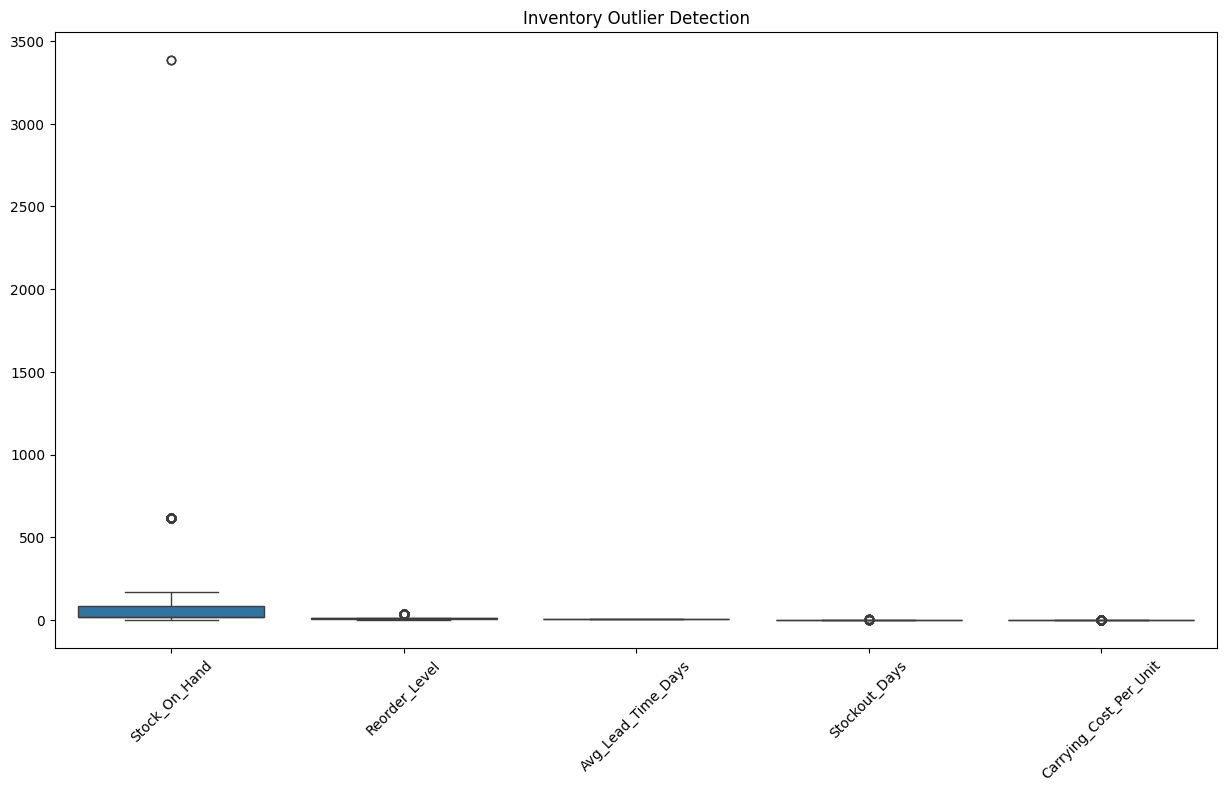

In [29]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=InventoryStockMovement_df[
    ['Stock_On_Hand', 'Reorder_Level', 'Avg_Lead_Time_Days',
     'Stockout_Days', 'Carrying_Cost_Per_Unit']
])

plt.xticks(rotation=45)
plt.title('Inventory Outlier Detection')
plt.show()

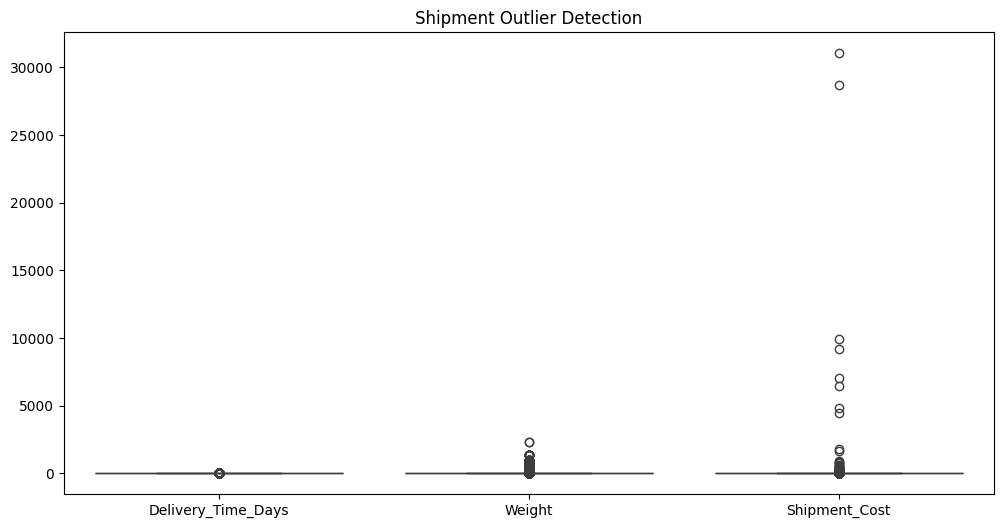

In [30]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=ShipmentDelivery_df[
    ['Delivery_Time_Days', 'Weight', 'Shipment_Cost']
])

plt.title('Shipment Outlier Detection')
plt.show()

In [31]:
InventoryStockMovement_df.nlargest(10, 'Stock_On_Hand')

,Product_ID,Warehouse_ID,Category,Stock_On_Hand,Reorder_Level,Reorder_Flag,Avg_Lead_Time_Days,Stockout_Days,Carrying_Cost_Per_Unit
673,1670498,PLANT14,Misc,3385,10,0,5,0,0.13
674,1685171,PLANT14,Misc,3385,10,0,5,0,0.13
675,1700693,PLANT14,Misc,3385,10,0,5,0,0.13
676,1666985,PLANT16,Misc,618,35,0,5,0,0.38
677,1668039,PLANT16,Misc,618,35,0,5,0,0.38
678,1668350,PLANT16,Misc,618,35,0,5,0,0.38
679,1668351,PLANT16,Misc,618,35,0,5,0,0.38
680,1668369,PLANT16,Misc,618,35,0,5,0,0.38
681,1668382,PLANT16,Misc,618,35,0,5,0,0.38
682,1668792,PLANT16,Misc,618,35,0,5,0,0.38


In [32]:
InventoryStockMovement_df.nlargest(10, 'Carrying_Cost_Per_Unit')

,Product_ID,Warehouse_ID,Category,Stock_On_Hand,Reorder_Level,Reorder_Flag,Avg_Lead_Time_Days,Stockout_Days,Carrying_Cost_Per_Unit
21,1660883,PLANT18,Misc,170,10,0,5,0,0.41
22,1664500,PLANT18,Misc,170,10,0,5,0,0.41
23,1666994,PLANT18,Misc,170,10,0,5,0,0.41
24,1668792,PLANT18,Misc,170,10,0,5,0,0.41
25,1669083,PLANT18,Misc,170,10,0,5,0,0.41
26,1669095,PLANT18,Misc,170,10,0,5,0,0.41
27,1669740,PLANT18,Misc,170,10,0,5,0,0.41
28,1669741,PLANT18,Misc,170,10,0,5,0,0.41
29,1671769,PLANT18,Misc,170,10,0,5,0,0.41
30,1673352,PLANT18,Misc,170,10,0,5,0,0.41


In [33]:
ShipmentDelivery_df.nlargest(10, 'Weight')

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
914,S000885,V555555_6,PLANT16,PORT09,2023-08-11,2023-08-11,0,2338.405126,V444_0,Delivered,GROUND,28711.873500,1,0
915,S000885,V555555_6,PLANT16,PORT09,2023-08-11,2023-08-11,0,2338.405126,V444_0,Delivered,GROUND,31050.278620,1,0
52962,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,73.807744,1,0
52963,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,3.455200,1,0
52964,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,3.455200,1,0
52965,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,3.455200,1,0
52966,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,3.455200,1,0
52967,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,1.499200,1,0
52968,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,1.499200,1,0
52969,S003491,V55555_4,PLANT03,PORT09,2023-07-04,2023-07-07,3,1356.760000,V444_0,Delivered,AIR,1.499200,1,0


In [34]:
ShipmentDelivery_df.nlargest(10, 'Shipment_Cost')

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
915,S000885,V555555_6,PLANT16,PORT09,2023-08-11,2023-08-11,0,2338.405126,V444_0,Delivered,GROUND,31050.278620,1,0
914,S000885,V555555_6,PLANT16,PORT09,2023-08-11,2023-08-11,0,2338.405126,V444_0,Delivered,GROUND,28711.873500,1,0
917,S000886,V555555_6,PLANT16,PORT09,2024-12-19,2024-12-19,0,749.400000,V444_0,Delivered,GROUND,9950.832960,1,0
916,S000886,V555555_6,PLANT16,PORT09,2024-12-19,2024-12-19,0,749.400000,V444_0,Delivered,GROUND,9201.432960,1,1
913,S000884,V555555_6,PLANT16,PORT09,2024-08-29,2024-08-29,0,527.534472,V444_0,Delivered,GROUND,7004.813739,1,0
912,S000884,V555555_6,PLANT16,PORT09,2024-08-29,2024-08-29,0,527.534472,V444_0,Delivered,GROUND,6477.279266,1,0
919,S000887,V555555_6,PLANT16,PORT09,2024-10-31,2024-10-31,0,360.800000,V444_0,Delivered,GROUND,4790.846720,1,0
918,S000887,V555555_6,PLANT16,PORT09,2024-10-31,2024-10-31,0,360.800000,V444_0,Delivered,GROUND,4430.046720,1,0
863,S000859,V555555_6,PLANT16,PORT09,2023-03-23,2023-03-23,0,133.224269,V444_0,Delivered,GROUND,1769.005130,1,0
862,S000859,V555555_6,PLANT16,PORT09,2023-03-23,2023-03-23,0,133.224269,V444_0,Delivered,GROUND,1635.780861,1,0


In [35]:
ShipmentDelivery_df.nlargest(10, 'Delivery_Time_Days')

,Shipment_ID,Customer,Warehouse_ID,Destination_Region,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
2,S000003,V55555_53,PLANT16,PORT09,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,AIR,10.267013,1,1
3,S000004,V55555_53,PLANT16,PORT09,2023-10-21,2023-10-26,5,16.16,V44_3,Delivered,AIR,10.267013,1,0
5,S000006,V55555_53,PLANT16,PORT09,2024-05-27,2024-06-01,5,92.80,V44_3,Delivered,AIR,10.267013,1,0
9,S000010,V55555_53,PLANT16,PORT09,2024-09-11,2024-09-16,5,62.20,V44_3,Delivered,AIR,10.267013,1,0
11,S000012,V55555_53,PLANT16,PORT09,2024-03-07,2024-03-12,5,14.30,V44_3,Delivered,AIR,10.267013,1,0
15,S000016,V55555_53,PLANT16,PORT09,2023-08-30,2023-09-04,5,52.70,V44_3,Delivered,AIR,10.267013,1,0
18,S000019,V55555_53,PLANT16,PORT09,2023-08-18,2023-08-23,5,227.20,V44_3,Delivered,AIR,10.267013,1,0
30,S000031,V55555_53,PLANT16,PORT09,2023-02-11,2023-02-16,5,32.90,V44_3,Delivered,AIR,10.267013,1,0
31,S000032,V55555_53,PLANT16,PORT09,2024-09-01,2024-09-06,5,13.36,V44_3,Delivered,AIR,10.267013,1,0
35,S000036,V55555_53,PLANT16,PORT09,2024-01-21,2024-01-26,5,171.22,V44_3,Delivered,AIR,10.267013,1,0


In [36]:
# Check repeated shipment IDs
duplicate_shipments = ShipmentDelivery_df[
    ShipmentDelivery_df.duplicated(
        subset='Shipment_ID', keep=False
    )
]

print(duplicate_shipments.sort_values('Shipment_ID').head(20))

    Shipment_ID   Customer Warehouse_ID Destination_Region Dispatch_Date  \
854     S000855   V55555_4      PLANT16             PORT09    2024-10-27   
855     S000855   V55555_4      PLANT16             PORT09    2024-10-27   
856     S000856   V55555_4      PLANT16             PORT09    2024-09-07   
857     S000856   V55555_4      PLANT16             PORT09    2024-09-07   
858     S000857  V555555_6      PLANT16             PORT09    2023-11-22   
859     S000857  V555555_6      PLANT16             PORT09    2023-11-22   
860     S000858  V555555_6      PLANT16             PORT09    2024-04-13   
861     S000858  V555555_6      PLANT16             PORT09    2024-04-13   
862     S000859  V555555_6      PLANT16             PORT09    2023-03-23   
863     S000859  V555555_6      PLANT16             PORT09    2023-03-23   
864     S000860  V555555_6      PLANT16             PORT09    2024-09-14   
865     S000860  V555555_6      PLANT16             PORT09    2024-09-14   
867     S000

In [37]:
# Compare shipment costs for repeated IDs

cost_check = (
    ShipmentDelivery_df
    .groupby('Shipment_ID')['Shipment_Cost']
    .agg(['count', 'min', 'max', 'mean', 'nunique'])
)

print(cost_check[cost_check['count'] > 1].head(20))

             count          min          max         mean  nunique
Shipment_ID                                                       
S000855          2    12.562558    13.585700    13.074129        2
S000856          2     7.537535     8.151420     7.844477        2
S000857          2   454.815954   491.857910   473.336932        2
S000858          2   525.892065   568.722732   547.307399        2
S000859          2  1635.780861  1769.005130  1702.392995        2
S000860          2   249.370488   269.680177   259.525333        2
S000861          2   721.653420   780.427643   751.040532        2
S000862          2   330.130710   357.017822   343.574266        2
S000863          2   136.963644   148.118489   142.541066        2
S000864          2   273.927288   296.236977   285.082133        2
S000865          2   143.196352   154.858812   149.027582        2
S000866          2   466.424255   504.411636   485.417946        2
S000867          2    20.316546    21.971203    21.143874     

In [38]:
cost_check['Cost_Difference_%'] = (
    (cost_check['max'] - cost_check['min'])
    / cost_check['min'] * 100
)

print(cost_check.sort_values(
    'Cost_Difference_%', ascending=False
).head(20))

             count       min       max       mean  nunique  Cost_Difference_%
Shipment_ID                                                                  
S004639         20  0.000000    3.4552   1.981760        3                inf
S005593         20  0.000000    3.4552   1.981760        3                inf
S007407         40  0.002120  101.8272  20.778690       20       4.802920e+06
S007360         40  0.002570  101.8272  20.778760       20       3.962669e+06
S008168         40  0.003587  101.8272  20.778918       20       2.838347e+06
S008169         40  0.003587  101.8272  20.778918       20       2.838347e+06
S007330         40  0.004216  101.8272  20.779016       20       2.415146e+06
S007835         40  0.004222  101.8272  20.779017       20       2.411876e+06
S007367         40  0.004590  101.8272  20.779074       20       2.218275e+06
S007764         40  0.004927  101.8272  20.779126       20       2.066564e+06
S008385         40  0.006342  101.8272  20.779346       20      

In [39]:
# Check whether repeated IDs have identical shipment details
cols = [
    'Customer',
    'Warehouse_ID',
    'Destination_Region',
    'Dispatch_Date',
    'Delivery_Date',
    'Delivery_Time_Days',
    'Weight',
    'Carrier_Name',
    'Shipment_Status',
    'Delivery_Mode',
    'Delivery_Accuracy_Flag',
    'Damage_Flag'
]

for col in cols:
    print(col, 
          ShipmentDelivery_df.groupby('Shipment_ID')[col]
          .nunique().value_counts().sort_index())

Customer Customer
1    9215
Name: count, dtype: int64
Warehouse_ID Warehouse_ID
1    9215
Name: count, dtype: int64
Destination_Region Destination_Region
1    9215
Name: count, dtype: int64
Dispatch_Date Dispatch_Date
1    9215
Name: count, dtype: int64
Delivery_Date Delivery_Date
1     888
2    8327
Name: count, dtype: int64
Delivery_Time_Days Delivery_Time_Days
1     888
2    8327
Name: count, dtype: int64
Weight Weight
1    9215
Name: count, dtype: int64
Carrier_Name Carrier_Name
1    9215
Name: count, dtype: int64
Shipment_Status Shipment_Status
1    9215
Name: count, dtype: int64
Delivery_Mode Delivery_Mode
1    9215
Name: count, dtype: int64
Delivery_Accuracy_Flag Delivery_Accuracy_Flag
1    9215
Name: count, dtype: int64
Damage_Flag Damage_Flag
1    6001
2    3214
Name: count, dtype: int64


In [40]:
# Find shipments with different delivery dates
date_ids = (
    ShipmentDelivery_df.groupby('Shipment_ID')['Delivery_Date']
    .nunique()
)

date_ids = date_ids[date_ids > 1].index

date_check = ShipmentDelivery_df[
    ShipmentDelivery_df['Shipment_ID'].isin(date_ids)
]

print(date_check.head(20).to_string())

    Shipment_ID             Customer Warehouse_ID Destination_Region Dispatch_Date Delivery_Date  Delivery_Time_Days    Weight Carrier_Name Shipment_Status Delivery_Mode  Shipment_Cost  Delivery_Accuracy_Flag  Damage_Flag
922     S000889  V555555555555555_29      PLANT12             PORT09    2023-12-09    2023-12-12                   3  2.543556       V444_0       Delivered        AIR          3.455200                       1            0
923     S000889  V555555555555555_29      PLANT12             PORT09    2023-12-09    2023-12-12                   3  2.543556       V444_0       Delivered        AIR          0.209589                       1            0
924     S000889  V555555555555555_29      PLANT12             PORT09    2023-12-09    2023-12-12                   3  2.543556       V444_0       Delivered        AIR          3.455200                       1            0
925     S000889  V555555555555555_29      PLANT12             PORT09    2023-12-09    2023-12-12                

In [41]:
damage_ids = (
    ShipmentDelivery_df.groupby('Shipment_ID')['Damage_Flag']
    .nunique()
)

damage_ids = damage_ids[damage_ids > 1].index

damage_check = ShipmentDelivery_df[
    ShipmentDelivery_df['Shipment_ID'].isin(damage_ids)
]

print(damage_check.head(20).to_string())

    Shipment_ID       Customer Warehouse_ID Destination_Region Dispatch_Date Delivery_Date  Delivery_Time_Days      Weight Carrier_Name Shipment_Status Delivery_Mode  Shipment_Cost  Delivery_Accuracy_Flag  Damage_Flag
916     S000886      V555555_6      PLANT16             PORT09    2024-12-19    2024-12-19                   0  749.400000       V444_0       Delivered        GROUND    9201.432960                       1            1
917     S000886      V555555_6      PLANT16             PORT09    2024-12-19    2024-12-19                   0  749.400000       V444_0       Delivered        GROUND    9950.832960                       1            0
982     S000892  V5555555555_1      PLANT12             PORT09    2024-03-11    2024-03-14                   3    0.534783       V444_0       Delivered        AIR          3.455200                       1            0
983     S000892  V5555555555_1      PLANT12             PORT09    2024-03-11    2024-03-14                   3    0.534783      

Unnecessary Columns

In [42]:
ShipmentDelivery_df.columns

Index(['Shipment_ID', 'Customer', 'Warehouse_ID', 'Destination_Region',
       'Dispatch_Date', 'Delivery_Date', 'Delivery_Time_Days', 'Weight',
       'Carrier_Name', 'Shipment_Status', 'Delivery_Mode', 'Shipment_Cost',
       'Delivery_Accuracy_Flag', 'Damage_Flag'],
      dtype='object')

In [43]:
print(ShipmentDelivery_df.nunique())

Shipment_ID               9215
Customer                    46
Warehouse_ID                 7
Destination_Region           1
Dispatch_Date              731
Delivery_Date              734
Delivery_Time_Days           6
Weight                    5833
Carrier_Name                 3
Shipment_Status              2
Delivery_Mode                2
Shipment_Cost             9225
Delivery_Accuracy_Flag       2
Damage_Flag                  2
dtype: int64


In [44]:
ShipmentDelivery_df['Destination_Region'].value_counts()

Destination_Region
PORT09    209402
Name: count, dtype: int64

In [45]:
ShipmentDelivery_df.shape

(209402, 14)

In [46]:
ShipmentDelivery_df['Destination_Region'].isnull().sum()

np.int64(0)

In [48]:
ShipmentDelivery_df.drop(columns=['Destination_Region'], inplace=True)

In [47]:
ShipmentDelivery_df.groupby('Shipment_ID')['Shipment_Cost'].nunique().value_counts()

Shipment_Cost
4     6228
20    2097
1      854
2       34
3        2
Name: count, dtype: int64

In [49]:
print(ShipmentDelivery_df.head())

  Shipment_ID   Customer Warehouse_ID Dispatch_Date Delivery_Date  \
0     S000001  V55555_53      PLANT16    2024-12-15    2024-12-18   
1     S000002  V55555_53      PLANT16    2023-03-28    2023-04-01   
2     S000003  V55555_53      PLANT16    2024-01-19    2024-01-24   
3     S000004  V55555_53      PLANT16    2023-10-21    2023-10-26   
4     S000005  V55555_53      PLANT16    2024-07-21    2024-07-24   

   Delivery_Time_Days  Weight Carrier_Name Shipment_Status Delivery_Mode  \
0                   3   14.30        V44_3       Delivered        AIR      
1                   4   87.94        V44_3       Delivered        AIR      
2                   5   61.20        V44_3       Delivered        AIR      
3                   5   16.16        V44_3       Delivered        AIR      
4                   3   52.34        V44_3       Delivered        AIR      

   Shipment_Cost  Delivery_Accuracy_Flag  Damage_Flag  
0      10.267013                       1            0  
1      10.267013

In [50]:
print(InventoryStockMovement_df.nunique())

Product_ID                1540
Warehouse_ID                19
Category                     1
Stock_On_Hand               18
Reorder_Level                7
Reorder_Flag                 2
Avg_Lead_Time_Days           1
Stockout_Days                4
Carrying_Cost_Per_Unit      10
dtype: int64


In [52]:
InventoryStockMovement_df.drop(columns=['Category'], inplace=True)
InventoryStockMovement_df.drop(columns=['Avg_Lead_Time_Days'], inplace=True)

In [53]:
float_cols = InventoryStockMovement_df.select_dtypes(include='float').columns

InventoryStockMovement_df[float_cols] = InventoryStockMovement_df[float_cols].round(2)

In [54]:
float_colss = ShipmentDelivery_df.select_dtypes(include='float').columns

ShipmentDelivery_df[float_colss] = ShipmentDelivery_df[float_colss].round(2)

In [55]:
InventoryStockMovement_df.head()

,Product_ID,Warehouse_ID,Stock_On_Hand,Reorder_Level,Reorder_Flag,Stockout_Days,Carrying_Cost_Per_Unit
0,1698815,PLANT15,149,10,0,0,0.28
1,1664419,PLANT17,6,10,1,1,0.09
2,1664426,PLANT17,6,10,1,1,0.09
3,1672826,PLANT17,6,10,1,2,0.09
4,1674916,PLANT17,6,10,1,3,0.09


In [57]:
ShipmentDelivery_df.head()

,Shipment_ID,Customer,Warehouse_ID,Dispatch_Date,Delivery_Date,Delivery_Time_Days,Weight,Carrier_Name,Shipment_Status,Delivery_Mode,Shipment_Cost,Delivery_Accuracy_Flag,Damage_Flag
0,S000001,V55555_53,PLANT16,2024-12-15,2024-12-18,3,14.30,V44_3,Delivered,AIR,10.27,1,0
1,S000002,V55555_53,PLANT16,2023-03-28,2023-04-01,4,87.94,V44_3,Delivered,AIR,10.27,1,0
2,S000003,V55555_53,PLANT16,2024-01-19,2024-01-24,5,61.20,V44_3,Delivered,AIR,10.27,1,1
3,S000004,V55555_53,PLANT16,2023-10-21,2023-10-26,5,16.16,V44_3,Delivered,AIR,10.27,1,0
4,S000005,V55555_53,PLANT16,2024-07-21,2024-07-24,3,52.34,V44_3,Delivered,AIR,10.27,1,0


Downloading the Cleaned Data

In [58]:
ShipmentDelivery_df.to_excel(
    'ShipmentDelivery_Cleaned.xlsx',
    index=False
)

InventoryStockMovement_df.to_excel(
    'InventoryStockMovement_Cleaned.xlsx',
    index=False
)

In [62]:

ShipmentDelivery_Cleaned = pd.read_excel('ShipmentDelivery_Cleaned.xlsx')

InventoryStockMovement_Cleaned = pd.read_excel('InventoryStockMovement_Cleaned.xlsx')

In [63]:
Merged_df = pd.merge(
    ShipmentDelivery_df,
    InventoryStockMovement_df,
    on='Warehouse_ID',
    how='left'
)

MemoryError: Unable to allocate 1.15 GiB for an array with shape (154616999, 1) and data type datetime64[ns]

In [64]:
print("Shipment:", ShipmentDelivery_df.shape)
print("Inventory:", InventoryStockMovement_df.shape)

print("Shipment memory:")
print(ShipmentDelivery_df.memory_usage(deep=True).sum() / 1024**3, "GB")

print("Inventory memory:")
print(InventoryStockMovement_df.memory_usage(deep=True).sum() / 1024**3, "GB")

Shipment: (209402, 13)
Inventory: (2036, 7)
Shipment memory:
0.08685972634702921 GB
Inventory memory:
0.0002124914899468422 GB


In [65]:
print(ShipmentDelivery_df['Warehouse_ID'].dtype)

print(InventoryStockMovement_df['Warehouse_ID'].dtype)

object
object


In [66]:
shipment_counts = ShipmentDelivery_df['Warehouse_ID'].value_counts()

inventory_counts = InventoryStockMovement_df['Warehouse_ID'].value_counts()

expected_rows = sum(
    shipment_counts.get(warehouse, 0) *
    inventory_counts.get(warehouse, 0)
    for warehouse in inventory_counts.index
)

print("Expected merge rows:", expected_rows)

Expected merge rows: 154616999


In [67]:
print("Shipment Warehouse IDs:")
print(ShipmentDelivery_df['Warehouse_ID'].value_counts())

print("\nInventory Warehouse IDs:")
print(InventoryStockMovement_df['Warehouse_ID'].value_counts())

Shipment Warehouse IDs:
Warehouse_ID
PLANT03    196953
PLANT12      8260
PLANT08      2021
PLANT13      1720
PLANT09       240
PLANT16       207
PLANT04         1
Name: count, dtype: int64

Inventory Warehouse IDs:
Warehouse_ID
PLANT03    781
PLANT01    220
PLANT13    150
PLANT04    134
PLANT05    127
PLANT10    121
PLANT02    116
PLANT16    113
PLANT11     96
PLANT12     57
PLANT07     29
PLANT06     26
PLANT08     21
PLANT17     20
PLANT18     12
PLANT09      8
PLANT14      3
PLANT15      1
CND9         1
Name: count, dtype: int64


In [68]:
WarehouseOperation_df = pd.read_excel('WarehouseOperation.xlsx')

In [69]:
WarehouseOperation_df['Warehouse_ID'].nunique()

WarehouseOperation_df['Warehouse_ID'].duplicated().sum()

np.int64(0)

In [70]:
Shipment_Merged_df = pd.merge(
    ShipmentDelivery_df,
    WarehouseOperation_df,
    on='Warehouse_ID',
    how='left',
    validate='many_to_one'
)

In [73]:
Inventory_Merged_df = pd.merge(
    InventoryStockMovement_df,
    WarehouseOperation_df,
    on='Warehouse_ID',
    how='left',
    validate='many_to_one'
)

In [74]:
print("Shipment:", Shipment_Merged_df.shape)

print("Inventory:", Inventory_Merged_df.shape)

Shipment: (209402, 24)
Inventory: (2036, 18)


In [75]:
print(Shipment_Merged_df['Warehouse_Capacity_Units'].isnull().sum())

print(Inventory_Merged_df['Warehouse_Capacity_Units'].isnull().sum())

0
0


In [76]:
Shipment_Merged_df.to_excel(
    'Shipment_Warehouse_Merged.xlsx',
    index=False
)

Inventory_Merged_df.to_excel(
    'Inventory_Warehouse_Merged.xlsx',
    index=False
)